# Assignment - FCNN classification, optimization and regularization

**Version**: 04-10-2026

Hi there! In this assignment, you will use fully connected neural networks (FCNN) to solve an adapted Question 1 of the winter 2023 exam in applied machine learning. The assignment covers two lectures:

- **Introduction to neural networks** (28 September and 5 October): building and training FCNNs, activation functions, optimizers, learning rate, batch size and epochs.
- **Optimization and regularization** (26 October): model size, early stopping, weight regularization, dropout and batch normalization.

You can start on Parts 1 and 2 of the questions right away, and add Part 3 after the 26 October lecture.

The assignment is posted as a Kaggle competition and is available here: https://www.kaggle.com/t/4a17f04939614a96b40429f413d3bdb0

To get you started, I have provided a complete working example. It is a real network that learns, but it is not very impressive, and you should be able to beat it.

When you are done, submit your results on the Kaggle webpage for this competition. If you do not like to show your score to everyone, you may use an anonymous username on Kaggle. However, I suggest you use your real name, after all it is just meant as an exercise and it is more fun that way. You can submit 5 times every day, so you can experiment with some stuff without being "locked in".

# Competition rules

**The spirit of the competition**

This competition is a playground for what you learn in class. The leaderboard is there to make it fun and to show you what works. Your real goal, though, is to understand *why* your model gets the score it does. A 68% that you can explain teaches you more than a lucky 72%, and explaining your choices is exactly what the exam asks of you. So be curious, try things, and enjoy it!

**What you may use**

1. **Fully connected neural networks.** Your submissions must come from fully connected networks (`Dense` layers) built with TensorFlow/Keras. The gradient boosting model below is a benchmark to beat, not a submission.
2. **The methods from class.** Use the models and techniques we have covered in class up to the submission deadline. Among other things, that includes:
   - activation functions, number of layers and neurons;
   - optimizers, learning rate, batch size and number of epochs;
   - early stopping, weight regularization, dropout and batch normalization.

   Preprocessing such as resizing, cropping, grayscale versus color, and scaling is allowed and encouraged.
3. **Only the competition data.** Train only on `Xtrain.npy` and `ytrain.npy`. Do not use the full PCam dataset, other external data or pretrained models. PCam is public, so its test labels can be found online, but using them would only fool yourself.
4. **Predictions come from your model.** Do not label test images by hand. Choose your model on your own validation set, not on the public leaderboard: the final ranking uses the other half of the test images (see "Kaggle" at the end).
5. **5 submissions per day.** Use them to test ideas. There is no prize for using them all.

**Good habits (and good exam practice)**

- Submit the starter model early, so you know your pipeline works.
- Change one thing at a time, so you know what made the difference.
- Keep a log of what you tried: the settings, the validation accuracy and what you concluded.
- Discuss ideas with your fellow students. That is how everyone learns more.

Good luck, and have fun!

# The problem

During the semester you have become very excited about the field of digital pathology, which is an area that is developing rapidly due to advancements in microscopy imaging hardware. These advancements have allowed digitizing glass slides into whole-slide images. You have recently read the paper by [Veeling et al. (2018)](https://arxiv.org/abs/1806.03962) and you are thrilled to see that the authors have derived a novel dataset, denoted PatchCamelyon (PCam), that will enable you to develop and benchmark your own machine learning models. As Veeling et al. (2018), you are primarily interested in developing machine learning models that, based on patches of whole-slide images of lymph node sections, can assist pathologists in tumor detection.

The primary objective is to perform image classification using the PCam dataset. The full dataset consists of 327,680 color images (96 x 96 pixels) extracted from histopathologic scans of lymph node sections. Each image is annotated with a binary label indicating presence of metastatic tissue. For this assignment, however, you are only going to use the subset of the data which has been made available on Kaggle.

# The data

Download the three files from the Kaggle page and put them in the same folder as this notebook:

| File | Contents | Shape |
|---|---|---|
| `Xtrain.npy` | Training images, RGB, pixel values 0-255 (`uint8`) | (26214, 96, 96, 3) |
| `ytrain.npy` | Training labels: 1 = metastatic (tumor) tissue, 0 = no tumor tissue | (26214,) |
| `Xtest.npy` | Test images, **without** labels. These are the images you predict for Kaggle | (1638, 96, 96, 3) |

The training images are 10% of the PCam training split, and the test images are 5% of the PCam test split. Both classes are about equally common, so a model that guesses has an accuracy of about 50%.

Two facts from the [PCam documentation](https://github.com/basveeling/pcam) are worth knowing:

- **The label is about the center of the image.** An image is labelled 1 if the center 32 x 32 pixel region contains at least one pixel of tumor tissue. Tumor tissue in the outer region of the image does not affect the label.
- **The test images come from other slides.** In PCam, no whole-slide image appears in more than one split. Your test images were therefore scanned from other lymph node sections than your training images. A validation set that you split off at random from `Xtrain`, on the other hand, contains images from the same slides as your training data.

# Hints to get you started (with a very simple model)

In [4]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # fewer TensorFlow start-up messages

import numpy as np
import pandas as pd
import tensorflow as tf
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split

In [5]:
# Load the data (the files must be in the same folder as this notebook).
# Note that there is no y_test! Kaggle keeps it, so you cannot "cheat".
X_train_raw = np.load('Xtrain.npy')
y_train_raw = np.load('ytrain.npy').reshape(-1)
X_test_raw = np.load('Xtest.npy')

print(f'Training images: {X_train_raw.shape}, {X_train_raw.dtype}')
print(f'Training labels: {y_train_raw.shape}, '
      f'images per class (0, 1): {np.bincount(y_train_raw)}')
print(f'Test images:     {X_test_raw.shape}')

Training images: (26214, 96, 96, 3), uint8
Training labels: (26214,), images per class (0, 1): [13129 13085]
Test images:     (1638, 96, 96, 3)


## A look at the images

Four training images from each class. The dashed square marks the center 32 x 32 pixel region that decides the label.

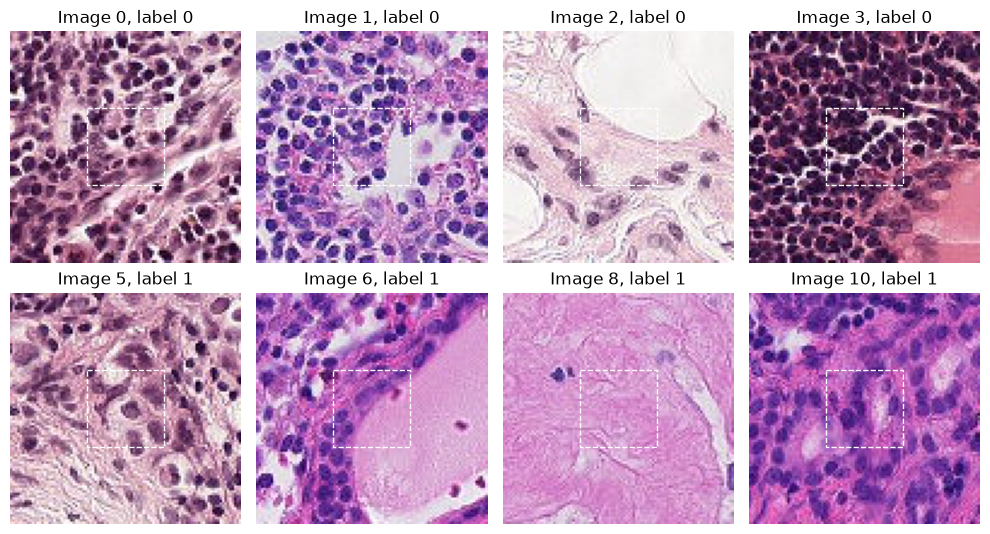

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for row, label in enumerate([0, 1]):
    first_four = np.flatnonzero(y_train_raw == label)[:4]
    for ax, i in zip(axes[row], first_four):
        ax.imshow(X_train_raw[i])
        ax.add_patch(plt.Rectangle((31.5, 31.5), 32, 32, fill=False,
                                   edgecolor='white', linestyle='--'))
        ax.set_title(f'Image {i}, label {label}')
        ax.axis('off')
plt.tight_layout()
plt.show()

## Preparing the images

At full size, an image has 96 x 96 x 3 = 27,648 values. Stored as 32-bit floats, the training images would take 26,214 x 27,648 x 4 bytes, or about 2.9 GB, and every neuron in the first layer would need 27,648 weights.

The function below therefore takes a (None, 96, 96, 3) array and turns it into a (None, 32, 32, 1) array: it resizes, converts to grayscale and normalizes the pixels to [0, 1]. An image then has 32 x 32 = 1,024 values. The size and the choice between grayscale and color are arguments, because they are among the things you can tune. This function might also become handy if the original images are too large for your hardware configuration.

In [7]:
def convert_sample(images, size=32, grayscale=True, batch_size=1024):
    # Resize (None, 96, 96, 3) uint8 images to (None, size, size, 1 or 3)
    # floats in [0, 1]. Works in batches to save memory.
    converted = []
    for start in range(0, len(images), batch_size):
        batch = tf.image.resize(images[start:start + batch_size], [size, size])
        if grayscale:
            batch = tf.image.rgb_to_grayscale(batch)
        converted.append((batch / 255.0).numpy())
    return np.concatenate(converted)


X_train_all = convert_sample(X_train_raw)
X_test = convert_sample(X_test_raw)
print(f'Shape of the resized training data: {X_train_all.shape}')
print(f'Shape of the resized test data:     {X_test.shape}')

Shape of the resized training data: (26214, 32, 32, 1)
Shape of the resized test data:     (1638, 32, 32, 1)


## A validation set

Kaggle gives you labels for the training images only. As in the lectures, we therefore split off a validation set: 80% for training and 20% for validation. `stratify` keeps the share of tumor images the same in both parts.

**Note:** When you do hyperparameter tuning, you should use the validation set. The test set should only be used for the final evaluation, which here means your Kaggle submission.

In [8]:
X_train, X_val, y_train, y_val = train_test_split(X_train_all, y_train_raw,
                                                  test_size=0.2,
                                                  stratify=y_train_raw,
                                                  random_state=42)
print(f'Training:   {X_train.shape}')
print(f'Validation: {X_val.shape}')

Training:   (20971, 32, 32, 1)
Validation: (5243, 32, 32, 1)


## The baseline to beat

Before we train a neural network, let us see what a shallow learner can do. In the lecture we noted that on small/medium tabular data, gradient boosting is often as good as or better than a neural network: it is the baseline to beat. Below, every pixel of the 32 x 32 grayscale images is a feature for `HistGradientBoostingClassifier` from the boosting lectures. It takes less than a minute.

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier

# One row per image and one column per pixel: (None, 32, 32, 1) -> (None, 1024)
hgb = HistGradientBoostingClassifier(random_state=42)
hgb.fit(X_train.reshape(len(X_train), -1), y_train)
hgb_accuracy = hgb.score(X_val.reshape(len(X_val), -1), y_val)
print(f'Gradient boosting, validation accuracy: {hgb_accuracy:.1%}')

Gradient boosting, validation accuracy: 78.1%


## A simple model

The network has the same layers as `our_first_nn` in the lecture: two hidden ReLU layers with 64 and 128 neurons, and a softmax output with one unit per class. `Flatten` turns each 32 x 32 x 1 image into a vector of 1,024 values.

In [10]:
tf.keras.utils.set_random_seed(42)
model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(32, 32, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(2, activation='softmax'),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,178 (289.76 KB)

 Trainable params: 74,178 (289.76 KB)

 Non-trainable params: 0 (0.00 B)

GRID SEARCH

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    # 'max_depth': [3, 5, 7, None],
    # 'min_samples_split': [2, 5, 10],
    # 'min_samples_leaf': [1, 2, 4],
    # 'max_features': [None, 'sqrt', 'log2'],
}

grid_search = GridSearchCV(
    estimator=tree.DecisionTreeClassifier(random_state=42), # RET TIL DEN RIGTIGE MODEL HER
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    refit=True,
 )
grid_search.fit(X_train, y_train)

best_dt = grid_search.best_estimator_
y_test_hat_grid = best_dt.predict(X_test)
accuracy_grid = accuracy_score(y_test, y_test_hat_grid)

print(f'Best parameters: {grid_search.best_params_}')
print(f'Best cross-validation accuracy: {grid_search.best_score_:.1%}')
print(f'Test accuracy: {accuracy_grid:.1%}')
print(f'Tree depth: {best_dt.get_depth()}')
print(f'Number of leaves: {best_dt.get_n_leaves()}')

We train with Adam for 10 epochs. `validation_data` makes Keras report the validation loss and accuracy after every epoch.

In [11]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=10,
                    verbose=2)

Epoch 1/10
656/656 - 3s - 5ms/step - accuracy: 0.5096 - loss: 0.6939 - val_accuracy: 0.5787 - val_loss: 0.6902
Epoch 2/10
656/656 - 2s - 3ms/step - accuracy: 0.5303 - loss: 0.6871 - val_accuracy: 0.6121 - val_loss: 0.6850
Epoch 3/10
656/656 - 1s - 2ms/step - accuracy: 0.5599 - loss: 0.6780 - val_accuracy: 0.6117 - val_loss: 0.6754
Epoch 4/10
656/656 - 2s - 2ms/step - accuracy: 0.5838 - loss: 0.6665 - val_accuracy: 0.6163 - val_loss: 0.6648
Epoch 5/10
656/656 - 1s - 2ms/step - accuracy: 0.6071 - loss: 0.6507 - val_accuracy: 0.6313 - val_loss: 0.6501
Epoch 6/10
656/656 - 1s - 2ms/step - accuracy: 0.6350 - loss: 0.6363 - val_accuracy: 0.6561 - val_loss: 0.6365
Epoch 7/10
656/656 - 1s - 2ms/step - accuracy: 0.6457 - loss: 0.6286 - val_accuracy: 0.6580 - val_loss: 0.6280
Epoch 8/10
656/656 - 2s - 3ms/step - accuracy: 0.6494 - loss: 0.6243 - val_accuracy: 0.6594 - val_loss: 0.6234
Epoch 9/10
656/656 - 1s - 2ms/step - accuracy: 0.6530 - loss: 0.6213 - val_accuracy: 0.6586 - val_loss: 0.6207
E

The function below plots the training and validation curves. Use it for every model you try: it is how you see whether a model under- or overfits.

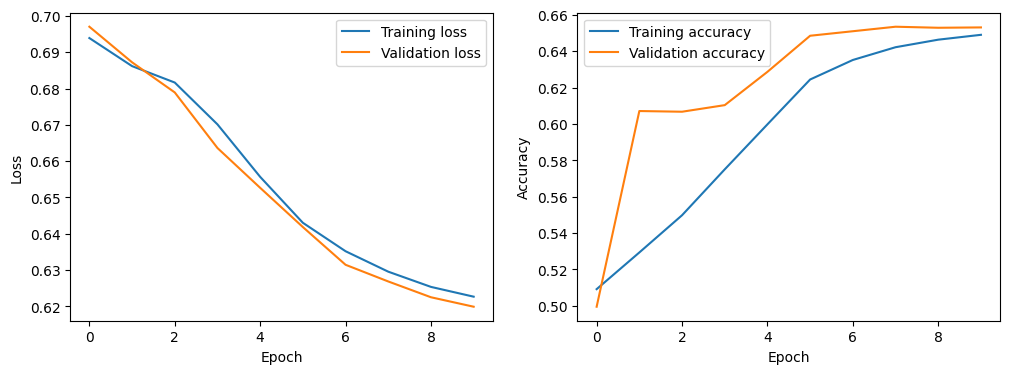

In [9]:
def plot_history(history):
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    ax_loss.plot(history.history['loss'], label='Training loss')
    ax_loss.plot(history.history['val_loss'], label='Validation loss')
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('Loss')
    ax_loss.legend()
    ax_acc.plot(history.history['accuracy'], label='Training accuracy')
    ax_acc.plot(history.history['val_accuracy'], label='Validation accuracy')
    ax_acc.set_xlabel('Epoch')
    ax_acc.set_ylabel('Accuracy')
    ax_acc.legend()
    plt.show()


plot_history(history)

After 10 epochs, the validation accuracy is 65.3%. That is clearly better than guessing (50%), but far below the gradient boosting baseline (78.3%). The training and validation curves are close, and both losses are still decreasing, so the model does not overfit yet. It may be too small, trained too briefly, or both. Finding out is what the questions are about. (Your numbers may differ slightly, depending on your hardware.)

# Your toolbox

Everything you need for the questions is in the two lectures. Here is the Keras syntax in one place.

| What | Lecture | Code |
|---|---|---|
| Feature scaling | Intro to NNs ("rules of thumb") | We divide by 255. Alternative: standardize each pixel with the mean and standard deviation of the **training** images, `mean, sd = X_train.mean(axis=0), X_train.std(axis=0)`, and apply `(X - mean) / sd` to training, validation and test images |
| Activation function | Intro to NNs, part 1 | `tf.keras.layers.Dense(64, activation='tanh')` |
| Optimizer and learning rate | Intro to NNs, parts 1-2 | `tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True)`, `tf.keras.optimizers.Adam(learning_rate=0.001)`; pass it to `model.compile(optimizer=...)` |
| Batch size and epochs | Intro to NNs, part 2 | `model.fit(..., batch_size=128, epochs=30)` |
| Tracking training (optional) | Intro to NNs, part 2 | `tf.keras.callbacks.TensorBoard(log_dir)` in `model.fit(..., callbacks=[...])` |
| Early stopping | Optimization and regularization | `tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)` in `model.fit(..., callbacks=[...])` |
| Weight regularization | Optimization and regularization | `tf.keras.layers.Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))` |
| Dropout | Optimization and regularization | `tf.keras.layers.Dropout(0.2)` after a hidden layer |
| Batch normalization | Optimization and regularization | `tf.keras.layers.BatchNormalization()` after a hidden layer |

**Tip:** As in the lecture on optimization and regularization, write a function that builds and compiles a model from a few arguments (size, activation, regularizer, dropout, batch normalization). It makes it easy to compare many models.

# Question (adapted from the exam)

Use FCNNs to perform image classification (tumor detection). Consider, among other things, the following.

**Part 1: the network** (Introduction to neural networks, part 1)
1. Different activation functions.
2. Different number of layers.
3. Different number of neurons in each layer.
4. Different image resolutions, and grayscale versus color. How important is the image resolution? Since the label is about the center of the image, you may also try to crop the center instead of resizing the whole image.

**Part 2: the training** (Introduction to neural networks, part 2)

5. Different optimizers.
6. Different learning rates.
7. Different batch sizes.
8. Different number of epochs. Use the training and validation curves to decide whether your model under- or overfits.

**Part 3: regularization** (Optimization and regularization)

9. Small, medium and large models.
10. Early stopping.
11. Weight regularization.
12. Dropout.
13. Batch normalization.

First add the methods in Part 3 to your model one at a time. Which method is, in isolation, best? Then combine them. Does the combination allow you to use a larger model?

**Part 4: your final model**

14. Choose your final model using the validation set, make predictions for the test set (below), and submit them on Kaggle.
15. Compare your validation accuracy with your Kaggle score. Are they close? If not, why might they differ? *Hint: see "The data".*
16. Compare your best FCNN with the gradient boosting baseline. Which is better? Why might a fully connected network find images difficult? (We return to this in the lectures on convolutional neural networks.)

**Note:** When you do hyperparameter tuning, you should use the validation set. The test set should only be used for the final evaluation. Keep a small table of what you tried and the validation accuracy you got. It is the quickest way to see what works, and it is what the exam asks of you.

# Making a submission

The below code makes predictions and then saves them (after checking they are in correct format).

The argmax converts probabilities to specific class predictions.

And finally convert to appropriate $\texttt{.csv}$ for Kaggle submit.

In [10]:
y_test_hat = model.predict(X_test, verbose=0)  # probabilities, shape (1638, 2)
y_test_hat = np.argmax(y_test_hat, axis=1)     # the most likely class, 0 or 1

y_test_hat_pd = pd.DataFrame({
    'Id': list(range(len(y_test_hat))),
    'Predicted': y_test_hat,
})

# Below is a small check that your output has the right type and shape
assert isinstance(y_test_hat_pd, pd.DataFrame)
assert list(y_test_hat_pd.columns) == ['Id', 'Predicted']
assert len(y_test_hat_pd) == 1638
assert set(y_test_hat_pd['Predicted']) <= {0, 1}

# If you pass the checks, the file is saved.
y_test_hat_pd.to_csv('y_test_hat_fcnn.csv', index=False)
print(y_test_hat_pd.head())

   Id  Predicted
0   0          0
1   1          1
2   2          1
3   3          0
4   4          1


# Kaggle

The metric used to score this assignment is accuracy: the share of test images you classify correctly.

You need a Kaggle account (free, you just need an email). When you submit your predictions, Kaggle gives you a score based on **some** of the test data (the public leaderboard). The final score is calculated using the **other** part of the test data (the private leaderboard), which is revealed when the competition closes. So you have no chance of looking at the test data for the competition, and tuning your model to the public leaderboard does not pay off.

# Appendix: how the data were made

You do not need to run this. The data come from [TensorFlow Datasets](https://www.tensorflow.org/datasets/catalog/patch_camelyon) and were extracted roughly like this:

```python
import tensorflow_datasets as tfds

ds_train, ds_test = tfds.load('patch_camelyon',
                              split=['train[:10%]', 'test[:5%]'],
                              batch_size=-1,       # all data, no batches
                              as_supervised=True)  # (image, label) pairs
X_train, y_train = tfds.as_numpy(ds_train)  # saved as Xtrain.npy and ytrain.npy
X_test, y_test = tfds.as_numpy(ds_test)     # Xtest.npy; Kaggle keeps y_test
```

The split strings show how to load only part of a dataset, which is useful if you are facing hardware constraints. You can read more about TensorFlow Datasets at https://www.tensorflow.org/datasets.